# **Part 5:** Spatial Join with HOLC and dependent variables 

    Code Last Updated: 10.8.26
    Author: Oliver Nguyen

## **Intro**

Ultimately we will only have 2 major tables: 

1. iNext response (From P3 Code)
2. Environmental Variables 

and we will join based on Hex ID to run KNN Random Forest 

---------

### **Dependent Variables**

For Dependent Variables, we have: 

- eBird data joined with HOLC grade and neighborhood ID
- Avonet 
- Impermeable surface (30 m)
- Canopy Level/complexity (10 m)
- NDVI (3 m)
- Distance to Highways 
- SF residential zoning shapefile

### **Response Variable**
Response variable: 

- Asymptotic Hill's Estimates for: 
  
  - Richness (q = 0)
  - Shannons (q = 1)
  - Simpsons (q = 2)


In total we should have:

1. 10 different habitat guild dataframes
2. non-native data frame
3. native data frame
4. all species dataframe 


In [1]:
import os
import pyproj

# Get the data directory from pyproj
proj_data_dir = pyproj.datadir.get_data_dir()
os.environ['PROJ_LIB'] = proj_data_dir

In [2]:
#Install and Load required packages in the notebook's environment if not already installed.  This is a one-time step.
#%conda install ipykernel
#%conda install -n sf_env ipykernel --update-deps --force-reinstall
#sf_env is the name of the conda environment
#%conda install duckdb pandas geopandas pyarrow
#%conda install shapely  
#Important for geometric operations
#%conda install rasterio
#import rasterio


import duckdb
import pandas as pd
import geopandas as gpd
from pathlib import Path
from shapely.geometry import Point


import numpy as np
import matplotlib.pyplot as plt
from rasterio.mask import mask


#Connect to DuckDB (in-memory)
con = duckdb.connect()
#con  # Optional: Print the connection object 

#Make sure your DuckDB connection has spatial capabilities
con.sql("INSTALL spatial")
con.sql("LOAD spatial")
con.sql("INSTALL json")
con.sql("LOAD json")

In [ ]:

#If you need to update conda you need to check version, run conda isntall conda (verison) and also conda update conda. Then run conda update --all, and verify version again.Kill the terminal and run the activation againf for conda_ch1
# %conda install conda=25.3.1.
# %conda update conda
# %conda init 
# %excute $SHELL
# %conda --version
#close terminal and then run conda activate the env.



In [3]:

#Working Directory Environment Setup

import os

current_directory = os.getcwd()
print(f"Current working directory: {current_directory}")

os.chdir("/home/oliver/Documents/redlining")
print(f"Current working directory: {current_directory}")



Current working directory: /home/oliver/Documents/redlining/code/SF
Current working directory: /home/oliver/Documents/redlining/code/SF


In [4]:
# Get current working directory
# Create a path relative to the current directory
#make sure to get the cleaned file for dependent data

data_file = Path("/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/redlining/SF_HOLC_cleaned.geojson")

HOLC = gpd.read_file(data_file)

#check it
import folium
HOLC.explore()

# Hexagons

<Axes: >

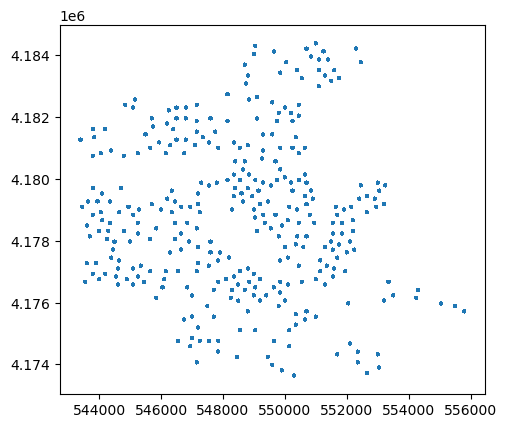

In [5]:
#Add in hexagons from P3 inext, make sure they're up to date 

# Use Path to construct the file path
path_file = Path("/home/oliver/Documents/redlining/data/SF/sfhex_100_filtered_11.16.26.geojson")


# Open the file - remove the square brackets
inext_hex = gpd.read_file(path_file)


inext_hex.plot()

In [6]:
import geopandas as gpd

inext_hex.crs

<Projected CRS: EPSG:32610>
Name: WGS 84 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 126°W and 120°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - British Columbia (BC); Northwest Territories (NWT); Nunavut; Yukon. United States (USA) - Alaska (AK).
- bounds: (-126.0, 0.0, -120.0, 84.0)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [7]:
inext_hex.columns

Index(['hex_id', 'grade', 'scientific_name', 'n_checklists_detected',
       'sum_observations', 'geometry'],
      dtype='str')

In [8]:
# ============================================================
# FIX: DEDUPLICATE HEX_PRJ BEFORE JOIN (We pretty much just want unique ID hexagons)
# ============================================================
# We should end up with 333 hexagons

hex_prj = inext_hex 
def prepare_unique_hexagons(hex_prj):
    """
    Remove duplicates from hexagon data
    """
    print("=" * 60)
    print("DEDUPLICATING HEXAGON DATA")
    print("=" * 60)
    print(f"Original rows: {len(hex_prj)}")
    print(f"Unique hex_ids: {hex_prj['hex_id'].nunique()}")
    
    # Check what columns exist
    print(f"\nColumns: {list(hex_prj.columns)}")
    

    # Option 1: If duplicates are true duplicates (all columns identical)
    # Just keep first occurrence
    hex_prj = hex_prj.drop(columns=['grade', 'scientific_name', 'n_checklists_detected','sum_observations'], errors='ignore')
    hex_unique = hex_prj.drop_duplicates().copy()
    
    print(f"\nAfter deduplication: {len(hex_unique)} rows")
    print(f"Unique hex_ids: {hex_unique['hex_id'].nunique()}")
    
    return hex_unique

# Deduplicate BEFORE running demographic calculation
hex_prj_clean = prepare_unique_hexagons(hex_prj)

# NOW run the demographic function with clean data
hex_prj_clean.head()


DEDUPLICATING HEXAGON DATA
Original rows: 98901
Unique hex_ids: 333

Columns: ['hex_id', 'grade', 'scientific_name', 'n_checklists_detected', 'sum_observations', 'geometry']

After deduplication: 333 rows
Unique hex_ids: 333


,hex_id,geometry
0,15_B,"POLYGON ((543395.991 4181201.584, 543345.991 4..."
317,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4..."
574,44_B,"POLYGON ((543545.991 4176611.65, 543495.991 41..."
894,65_B,"POLYGON ((543595.991 4177217.868, 543545.991 4..."
1178,72_B,"POLYGON ((543595.991 4178430.303, 543545.991 4..."


## Polygons

In [9]:

## Socioeconomic ##-----------

nhgis = gpd.read_file(Path('./data/SF/dependent_var/nhgis_SF_join.shp')) #load in shapefile 


## Urban Infrastructure ## -----------
### zoning 
zone_sf = gpd.read_file(Path('./data/SF/dependent_var/SanFrancisco_zoning.shp')) #load in shapefile 



### pollution, we don't use this in the final model
#pollution_sf = pd.read_csv(Path("../data/dependent_var/cesar_pollutiondata_10_29_24.csv")) #read csv 

#we'll have to join via columns in the next steps



In [15]:

#Data Preparation and Transformation

#Add together rasters and shapefiles for HOLC ID neighborhoods 

# Project data
#shapefiles 
crs = "EPSG:32610" # UTM Zone 10N, for San Francisco
holc_prj = HOLC.to_crs(crs)
nhgis_prj = nhgis.to_crs(crs)
zone_sf_prj = zone_sf.to_crs(crs)
hex_prj = hex_prj_clean.to_crs(crs) 
nhgis_prj.explore()





## Rasters

These shapefiles were create in other notebooks that created dependent variables. They have "P0[#]_[File_Name].ipynb" in the folder. 

1. NDVI
2. Highway Distance
3. Distance to Parks
4. FHD (Vegetative Complexity)

In [10]:
#%conda install rioxarray

import rioxarray as rxr
#Takes about 2 minutes
#Reproject the data using the crs from the roads layer
#upload raster data as rasterio objects 
### impermable surfaces (we're just going to grab the one from LA for now since SF is messed up and too low resolution, it also includes SF Bay Area)
imperm = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_LA_redlining/data/dependent_var/ca_2021_ccap_v2_hires_impervious_20240108.tif'),
                              masked=True).squeeze()


In [20]:

highway = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_highway_sf_3m.tif'),
                            
                            masked=True).squeeze()

parks = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/euc_park_sf_3m.tif'),
                            
                            masked=True).squeeze()

canopy = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/fhd_final.tif'),
                           masked=True).squeeze()

ndvi = rxr.open_rasterio(Path('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/dependent_var/ndvi_sf_aug2023.tif'), 
                         masked=True).squeeze()


In [16]:
# First, we neeed to cut down impervious surface
print("Imperm CRS:", imperm.rio.crs)
print("HOLC CRS:", HOLC.crs)

# Reproject HOLC to match the raster CRS
holc_reproj = HOLC.to_crs(imperm.rio.crs)

# Now get bounds and clip
bbox = holc_reproj.total_bounds
print("Bbox:", bbox)

# Check if bounds overlap with raster bounds
print("Raster bounds:", imperm.rio.bounds())

# Clip the raster
imperm_clipped = imperm.rio.clip_box(
    minx=bbox[0],
    miny=bbox[1],
    maxx=bbox[2],
    maxy=bbox[3]
)



Imperm CRS: EPSG:5070
HOLC CRS: EPSG:4326
Bbox: [-2283945.5650474   1948293.47081641 -2272125.85004564  1959839.12903064]
Raster bounds: (-2356246.37438353, 1258586.50905489, -1823800.37438353, 2453525.50905489)


# Canopy

We accidentally didn't use the correct EPGS for SF, according to 3DEP report: https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/metadata/CA_SanFrancisco_B23/CA_SanFrancisco_1_B23/reports/USGS_CA_SanFrancisco_1_B23_Summary_Report.pdf they used 7131

In [17]:
# Set the correct CRS for canopy
canopy_corrected = canopy.rio.write_crs('EPSG:7131', inplace=False)

# Now reproject to match hexagons
canopy_prj = canopy_corrected.rio.reproject(hex_prj_clean.crs)

# Verify it works
print("Corrected canopy bounds:", canopy_prj.rio.bounds())
print("Hexagon bounds:", hex_prj_clean.total_bounds)

from shapely.geometry import box
canopy_bbox = box(*canopy_prj.rio.bounds())
hex_bbox = box(*hex_prj_clean.total_bounds)
print("Overlaps?", canopy_bbox.intersects(hex_bbox))
canopy_prj.rio.crs



Corrected canopy bounds: (542577.4557813618, 4172310.0431112694, 559359.1589995513, 4187982.16266421)
Hexagon bounds: [ 543345.9912916  4173580.56090403  555845.9912916  4184434.74596479]
Overlaps? True


CRS.from_wkt('PROJCS["WGS 84 / UTM zone 10N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32610"]]')

In [18]:
#reproject all rasters to same crs
#takes about 4 minutes
ndvi_prj = ndvi.rio.reproject(crs)

highway_prj = highway.rio.reproject(crs)

parks_prj = parks.rio.reproject(crs)

imperm_prj = imperm_clipped.rio.reproject(crs)



# Export Raster images


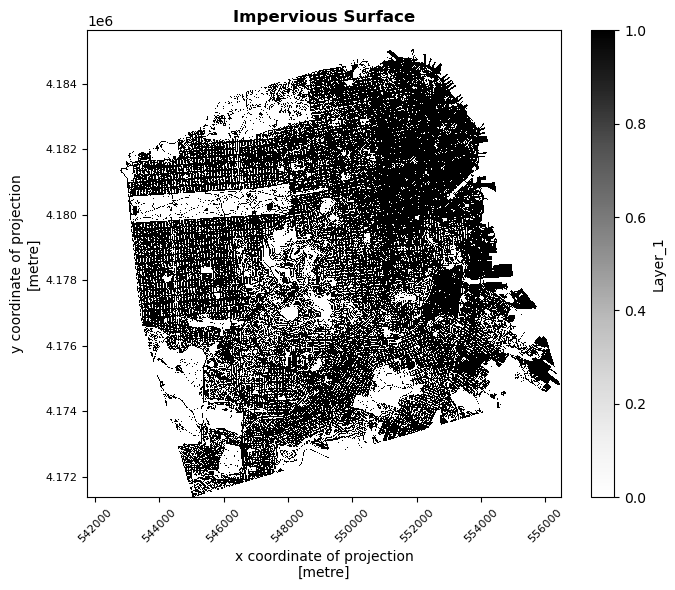

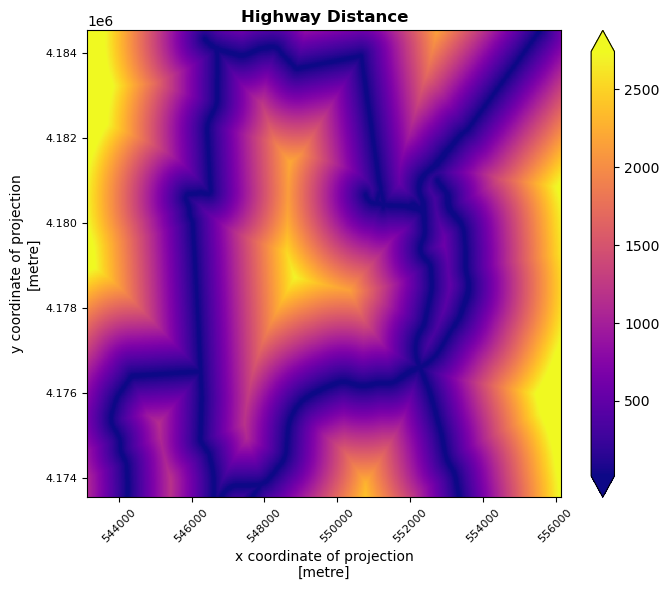

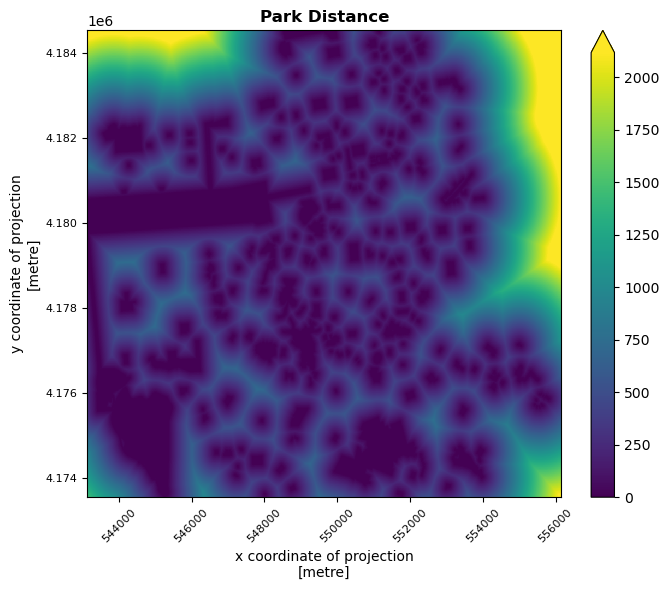

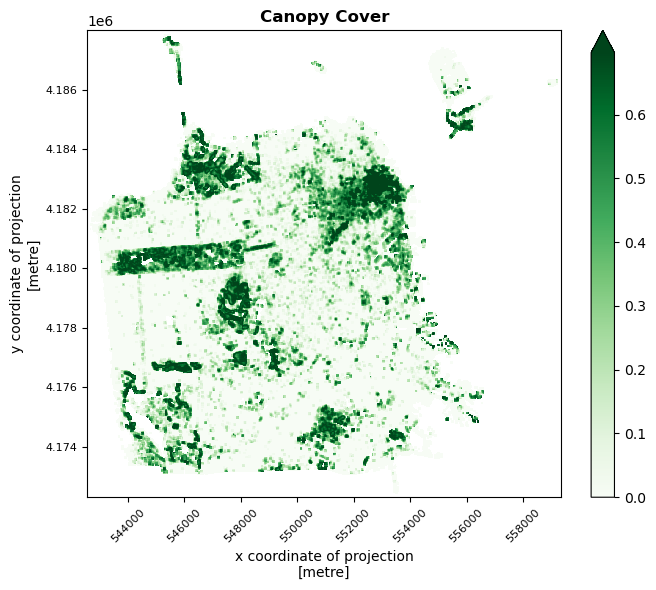

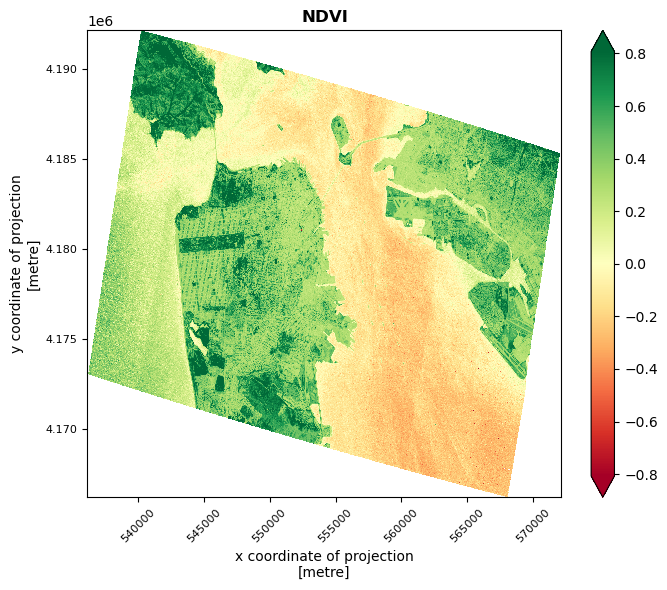

In [26]:
import os

downsample = 5
out_dir = "../results_images"
os.makedirs(out_dir, exist_ok=True)
date = "4.16.26"

layers = [
    # (raster,     title,                 colormap,  file name)
    (imperm_prj,  "Impervious Surface",  "Greys",   "impervious"),
    (highway_prj, "Highway Distance",    "plasma",  "highway_dist"),
    (parks_prj,   "Park Distance",       "viridis",  "park_dist"),
    (canopy_prj,  "Canopy Cover",        "Greens",  "canopy"),
    (ndvi_prj,    "NDVI",                "RdYlGn",  "ndvi"),
]

for da, title, cmap, fname in layers:
    fig, ax = plt.subplots(figsize=(7, 6))
    da[::downsample, ::downsample].plot(ax=ax, cmap=cmap, robust=True)
    ax.set_title(title, fontweight="bold")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    fig.tight_layout()
    fig.savefig(f"{out_dir}/{fname}_{date}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)   # frees memory so figures don't pile up


In [ ]:
#%pip install contextily
import contextily as ctx

# Get the bounds of the raster
left, bottom, right, top = ndvi_prj.rio.bounds()

fig, ax = plt.subplots(figsize=(12, 8))

# Plot a downsampled version of the raster
im = ax.imshow(ndvi_prj, extent=[left, right, bottom, top], 
               cmap='RdYlGn')

# Add a basemap
#ctx.add_basemap(ax, crs=ndvi.rio.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)

plt.colorbar(im, label='NDVI')
plt.title('NDVI with Basemap')
plt.axis('off')
plt.show()

# Raster Stats

In [28]:
import numpy as np
#%conda install rasterstats
#%conda install xarray

import rasterstats
import xarray as xr
from rasterstats import zonal_stats


# 1. RESET INDEX FIRST (crucial step!)
hex_prj_clean = hex_prj_clean.reset_index(drop=True)

# NDVI stats
ndvi_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    ndvi_prj.values,
    affine=ndvi_prj.rio.transform(),  # Use NDVI's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Highway stats
highway_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    highway_prj.values,
    affine=highway_prj.rio.transform(),  # Use Highway's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Park stats
parks_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    parks_prj.values,
    affine=highway_prj.rio.transform(),  # Use parks transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Impervious stats
imperm_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    imperm_prj.values,
    affine=imperm_prj.rio.transform(),  # Use Impervious's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Canopy stats
canopy_stats = rasterstats.zonal_stats(
    hex_prj_clean.geometry,
    canopy_prj.values,
    affine=canopy_prj.rio.transform(),  # Use Canopy's transform
    nodata=np.nan,
    all_touched=True,
    stats=['min', 'max', 'mean', 'count', 'median', 'std', 'majority']
)

# Convert to DataFrames with suffixes
ndvi_df = pd.DataFrame(ndvi_stats).add_suffix('_ndvi')
highway_df = pd.DataFrame(highway_stats).add_suffix('_highway')
parks_df = pd.DataFrame(parks_stats).add_suffix('_parks')
imperm_df = pd.DataFrame(imperm_stats).add_suffix('_imperm')
canopy_df = pd.DataFrame(canopy_stats).add_suffix('_canopy')

# Join all
result_gdf = hex_prj_clean.join([ndvi_df, highway_df, parks_df, imperm_df, canopy_df])

print(result_gdf.head())
print(f"NA values after fixing: {result_gdf['mean_ndvi'].isna().sum()}")


# 5. Verify
print(f"Total hexagons: {len(result_gdf)}")
print(f"\nNA counts per variable:")
print(result_gdf[['mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'mean_parks']].isna().sum())
print(f"\nSample data:")
print(result_gdf[['mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'mean_parks']].head(10))


  hex_id                                           geometry  min_ndvi  \
0   15_B  POLYGON ((543395.991 4181201.584, 543345.991 4...  0.254963   
1   21_C  POLYGON ((543445.991 4179036.521, 543395.991 4...  0.213248   
2   44_B  POLYGON ((543545.991 4176611.65, 543495.991 41...  0.218430   
3   65_B  POLYGON ((543595.991 4177217.868, 543545.991 4...  0.209496   
4   72_B  POLYGON ((543595.991 4178430.303, 543545.991 4...  0.226087   

   max_ndvi  mean_ndvi  count_ndvi  std_ndvi  median_ndvi  majority_ndvi  \
0  0.699268   0.416139        1029  0.107304     0.372334       0.313625   
1  0.669190   0.378044        1048  0.093760     0.351401       0.328507   
2  0.544557   0.316655        1030  0.057492     0.301282       0.277842   
3  0.551691   0.314890        1050  0.062287     0.302539       0.209496   
4  0.522994   0.323699        1049  0.061197     0.305067       0.260724   

   min_highway  ...  std_imperm  median_imperm  majority_imperm  min_canopy  \
0  2465.921387  ...    0.

Canopy NoData value: nan
Canopy has NaN: 15307696
Canopy value range: 0.0 to 1.3112495


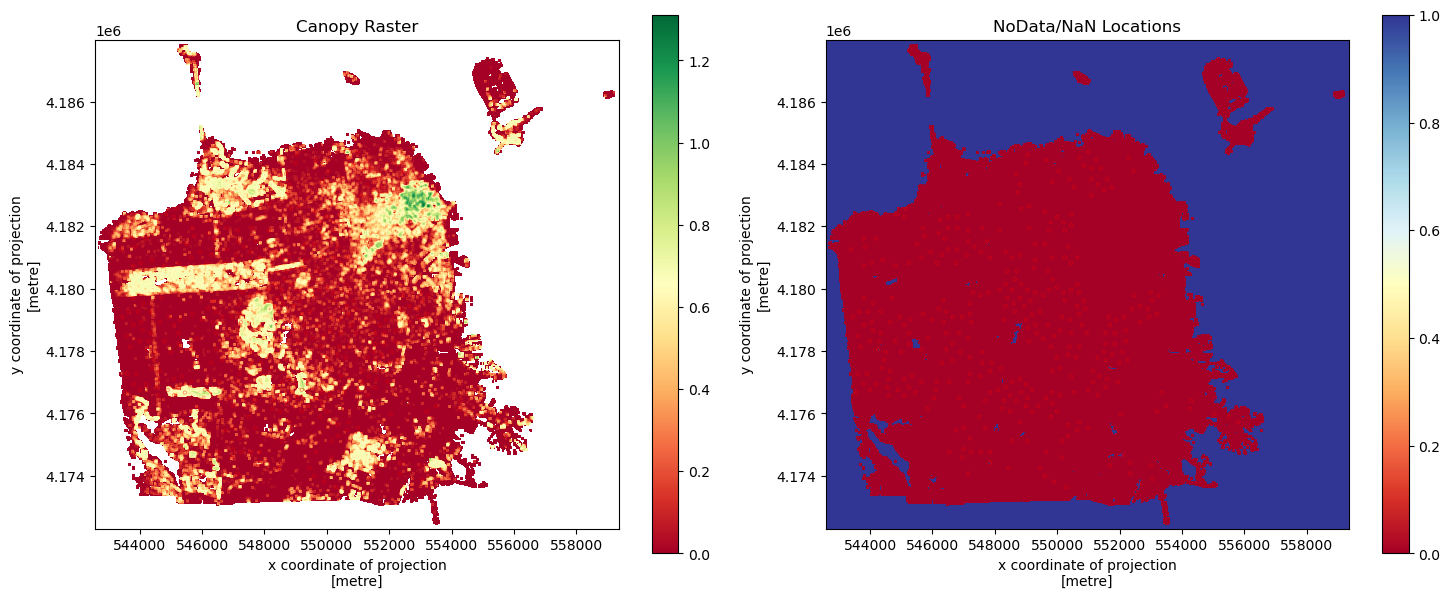

In [29]:
# Check NoData handling
print("Canopy NoData value:", canopy_prj.rio.nodata)
print("Canopy has NaN:", canopy_prj.isnull().sum().values)
print("Canopy value range:", canopy_prj.min().values, "to", canopy_prj.max().values)

# Visualize NoData locations
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Plot raster
canopy_prj.plot(ax=ax[0], cmap='RdYlGn')
ax[0].set_title('Canopy Raster')

# Plot NaN mask
canopy_prj.isnull().plot(ax=ax[1], cmap='RdYlBu')
ax[1].set_title('NoData/NaN Locations')

# Overlay hexagons
hex_prj_clean.boundary.plot(ax=ax[0], color='red', linewidth=0.5, alpha=0.5)
hex_prj_clean.boundary.plot(ax=ax[1], color='red', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()

# NHGIS Percentages

In [30]:

nhgis_prj = nhgis_prj[['AMP3E001', 'AMP3E003', 'AMP3E004', 'AMP3E005', 'AMP3E006', 
                       'AMP3E007', 'AMP3E008', 'AMR8E001', 'AMP3E012', 'geometry']]
                       

nhgis_prj = nhgis_prj.rename(columns={
    'AMP3E001': 'TOTPOP',
    'AMP3E003': 'NH_WHITE',
    'AMP3E004': 'NH_BLACK',
    'AMP3E005': 'NH_AMIN',
    'AMP3E006': 'NH_ASIAN',
    'AMP3E007': 'NH_NHPI',
    'AMP3E008': 'NH_OTHER',
    'AMR8E001': 'MED_INCOME',
    'AMP3E012': 'LATINE'
})


#nhgis_join = gpd.sjoin(hex_prj_clean, nhgis_prj1, how='inner', predicate='intersects') #check if it works using .head()


"""
# Create percentage columns for each demographic group
nhgis_join['WHITE_PER'] = nhgis_join['NH_WHITE'] / nhgis_join['TOTPOP']
nhgis_join['BLACK_PER'] = nhgis_join['NH_BLACK'] / nhgis_join['TOTPOP']
nhgis_join['AMIN_PER'] = nhgis_join['NH_AMIN'] / nhgis_join['TOTPOP']
nhgis_join['ASIAN_PER'] = nhgis_join['NH_ASIAN'] / nhgis_join['TOTPOP']
nhgis_join['NHPI_PER'] = nhgis_join['NH_NHPI'] / nhgis_join['TOTPOP']
nhgis_join['OTHER_PER'] = nhgis_join['NH_OTHER'] / nhgis_join['TOTPOP']
nhgis_join['LATINE_PER'] = nhgis_join['LATINE'] / nhgis_join['TOTPOP']

# Handle any potential division by zero errors (if there are census tracts with zero population)
percentage_columns = ['WHITE_PER', 'BLACK_PER', 'AMIN_PER', 'ASIAN_PER', 'NHPI_PER', 'OTHER_PER', 'LATINE_PER']
nhgis_join[percentage_columns] = nhgis_join[percentage_columns].fillna(0)

# You might want to multiply by 100 to get actual percentages
nhgis_join[percentage_columns] = nhgis_join[percentage_columns] * 100

# Check the new columns
print(nhgis_join[['TOTPOP'] + percentage_columns].head())

"""

"\n# Create percentage columns for each demographic group\nnhgis_join['WHITE_PER'] = nhgis_join['NH_WHITE'] / nhgis_join['TOTPOP']\nnhgis_join['BLACK_PER'] = nhgis_join['NH_BLACK'] / nhgis_join['TOTPOP']\nnhgis_join['AMIN_PER'] = nhgis_join['NH_AMIN'] / nhgis_join['TOTPOP']\nnhgis_join['ASIAN_PER'] = nhgis_join['NH_ASIAN'] / nhgis_join['TOTPOP']\nnhgis_join['NHPI_PER'] = nhgis_join['NH_NHPI'] / nhgis_join['TOTPOP']\nnhgis_join['OTHER_PER'] = nhgis_join['NH_OTHER'] / nhgis_join['TOTPOP']\nnhgis_join['LATINE_PER'] = nhgis_join['LATINE'] / nhgis_join['TOTPOP']\n\n# Handle any potential division by zero errors (if there are census tracts with zero population)\npercentage_columns = ['WHITE_PER', 'BLACK_PER', 'AMIN_PER', 'ASIAN_PER', 'NHPI_PER', 'OTHER_PER', 'LATINE_PER']\nnhgis_join[percentage_columns] = nhgis_join[percentage_columns].fillna(0)\n\n# You might want to multiply by 100 to get actual percentages\nnhgis_join[percentage_columns] = nhgis_join[percentage_columns] * 100\n\n# Check t

In [31]:
#add zoning and use area to see the % of the polygon designated as single/multi 
#also add in pop/dense 

#we need to calculate zone area 

hex_prj = hex_prj_clean
# Calculate area in square meters (if using a projected CRS)
zone_sf_prj['area_m2'] = zone_sf_prj.geometry.area
hex_prj['area_m2'] = hex_prj.geometry.area

zone_join = gpd.sjoin(hex_prj, zone_sf_prj, how='inner', predicate='intersects') #check if it works using .head()

#now calc percentages
# First, let's get the proper intersection geometries (not just the overlapping polygons)
# This creates actual intersection geometries
overlay = gpd.overlay(hex_prj, zone_sf_prj, how='intersection')

# Calculate the area of each intersection
overlay['intersection_area'] = overlay.geometry.area

# Group by HOLC polygon ID and zoning type to sum up areas
# Assuming 'holc_id' is your HOLC polygon identifier and 'zone_type' is your zoning category
# Replace these with your actual column names
grouped = overlay.groupby(['hex_id', 'Zoning']).agg({'intersection_area': 'sum'}).reset_index()

# Merge with original HOLC data to get the total area of each HOLC polygon
# Assuming 'holc_id' is your HOLC polygon identifier
merged = grouped.merge(hex_prj[['hex_id', 'area_m2']], on='hex_id')

# Calculate percentage
merged['percentage'] = (merged['intersection_area'] / merged['area_m2']) * 100

# View the results
print(merged[['hex_id', 'Zoning', 'percentage']])

# If you want to pivot this into a more readable format with HOLC grades as rows and zoning types as columns:
#pivot_table = merged.pivot(index='hex_id', columns='Zoning', values='percentage')
# Fix for the NameError
# First create the pivot table
aggregated = merged.groupby(['hex_id', 'Zoning'])['percentage'].agg('sum').reset_index()
pivot_table = aggregated.pivot(index='hex_id', columns='Zoning', values='percentage')
pivot_table = pivot_table.fillna(0)


print(pivot_table.fillna(0))  # Fill NaN with 0 for areas with no intersection


     hex_id  Zoning  percentage
0    1003_B     1.0    2.094441
1    1014_B     2.0   79.783716
2    1030_B     1.0   74.534527
3    1030_B     2.0    0.397367
4    1037_C     2.0   61.491672
..      ...     ...         ...
350   840_B     1.0   70.341328
351   847_B     2.0   67.928548
352   865_B     1.0   35.736822
353   865_B     2.0   25.088886
354   877_B     1.0   52.187720

[355 rows x 3 columns]
Zoning        1.0        2.0
hex_id                      
1003_B   2.094441   0.000000
1014_B   0.000000  79.783716
1030_B  74.534527   0.397367
1037_C   0.000000  61.491672
1080_A  62.124948   0.000000
...           ...        ...
838_B   58.903729   0.000000
840_B   70.341328   0.000000
847_B    0.000000  67.928548
865_B   35.736822  25.088886
877_B   52.187720   0.000000

[319 rows x 2 columns]


In [32]:

# ============================================================
# COMPLETE WORKFLOW WITH POPULATION DENSITY
# ============================================================


def calculate_hex_demographics_with_density(hex_prj_clean, nhgis_prj):
    """
    Complete workflow: demographics + population density
    """
    # 1. CLEAN MEDIAN INCOME DATA FIRST
    print("=" * 60)
    print("CLEANING MEDIAN INCOME DATA")
    print("=" * 60)
    
    # Check for negative/invalid values
    invalid_income = nhgis_prj[nhgis_prj['MED_INCOME'] < 0]
    print(f"Block groups with invalid income: {len(invalid_income)}/{len(nhgis_prj)}")
    
    if len(invalid_income) > 0:
        print(f"Invalid income values found: {invalid_income['MED_INCOME'].unique()}")
    
    # Replace invalid values with NaN
    nhgis_prj['MED_INCOME'] = nhgis_prj['MED_INCOME'].apply(
        lambda x: np.nan if x < 0 else x
    )
    
    # 1. Calculate percentages on block groups
    demographic_cols = ['NH_WHITE', 'NH_BLACK', 'NH_AMIN', 'NH_ASIAN', 
                       'NH_NHPI', 'NH_OTHER', 'LATINE']
    
    for col in demographic_cols:
        pct_col = col + '_PER'
        nhgis_prj[pct_col] = np.where(
            nhgis_prj['TOTPOP'] > 0,
            (nhgis_prj[col] / nhgis_prj['TOTPOP']) * 100,
            0
        )
    
    # POC percentage
    nhgis_prj['POC_PER'] = np.where(
        nhgis_prj['TOTPOP'] > 0,
        ((nhgis_prj['NH_BLACK'] + nhgis_prj['NH_AMIN'] + nhgis_prj['NH_ASIAN'] + 
          nhgis_prj['NH_NHPI'] + nhgis_prj['NH_OTHER'] + nhgis_prj['LATINE']) / 
         nhgis_prj['TOTPOP']) * 100,
        0
    )
    
    # Block group area and density
    nhgis_prj['bg_area_sqkm'] = nhgis_prj.geometry.area / 1_000_000
    nhgis_prj['bg_pop_density'] = np.where(
        nhgis_prj['bg_area_sqkm'] > 0,
        nhgis_prj['TOTPOP'] / nhgis_prj['bg_area_sqkm'],
        0
    )
    
    # 2. Spatial join
    nhgis_join = gpd.sjoin(hex_prj_clean, nhgis_prj, how='left', predicate='intersects')
    
    # 3. Population-weighted aggregation
    def weighted_average(group, value_col, weight_col='TOTPOP'):
        weights = group[weight_col]
        values = group[value_col]
        if weights.sum() == 0:
            return 0
        return (values * weights).sum() / weights.sum()
    
    # Demographic percentage columns
    demographic_pct_cols = ['NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 
                           'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 
                           'LATINE_PER', 'POC_PER']
    
    # Aggregation dictionary
    agg_dict = {
        'TOTPOP': 'sum',
        'MED_INCOME': lambda x: weighted_average(
            pd.DataFrame({'MED_INCOME': nhgis_join.loc[x.index, 'MED_INCOME'], 
                         'TOTPOP': nhgis_join.loc[x.index, 'TOTPOP']}), 
            'MED_INCOME'
        )
    }
    
    # Add demographic percentages
    for col in demographic_pct_cols:
        agg_dict[col] = lambda x, col=col: weighted_average(
            pd.DataFrame({col: nhgis_join.loc[x.index, col], 
                         'TOTPOP': nhgis_join.loc[x.index, 'TOTPOP']}), 
            col
        )
    
    # Aggregate by hexagon
    hex_demographics = nhgis_join.groupby('hex_id').agg(agg_dict).reset_index()
    
    # 4. Calculate hexagon area
    hex_prj_clean['area_sqkm'] = hex_prj_clean.geometry.area / 1_000_000
    hex_prj_clean['area_sqm'] = hex_prj_clean.geometry.area
    
    # 5. Merge area to demographics
    hex_demographics = hex_demographics.merge(
        hex_prj_clean[['hex_id', 'area_sqkm', 'area_sqm']], 
        on='hex_id', 
        how='left'
    )
    
    # 6. Calculate population density
    hex_demographics['pop_density_sqkm'] = np.where(
        hex_demographics['area_sqkm'] > 0,
        hex_demographics['TOTPOP'] / hex_demographics['area_sqkm'],
        0
    )
    
    hex_demographics['pop_density_sqm'] = np.where(
        hex_demographics['area_sqm'] > 0,
        hex_demographics['TOTPOP'] / hex_demographics['area_sqm'],
        0
    )
    
    
    # 7. Merge back to hexagon geometry
    hex_final = hex_prj_clean.merge(hex_demographics, on='hex_id', how='left')
    
    # Remove duplicate area columns
    hex_final = hex_final.drop(columns=['area_sqkm_y', 'area_sqm_y'], errors='ignore')
    hex_final = hex_final.rename(columns={
        'area_sqkm_x': 'area_sqkm',
        'area_sqm_x': 'area_sqm'    })
    
    return hex_final

# Run the complete workflow
hex_final = calculate_hex_demographics_with_density(hex_prj_clean, nhgis_prj)

# ============================================================
# SUMMARY STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("FINAL DATASET SUMMARY")
print("=" * 60)
print(f"Total hexagons: {len(hex_final)}")
print(f"\nColumns: {list(hex_final.columns)}")

print("\n" + "=" * 60)
print("POPULATION DENSITY STATISTICS")
print("=" * 60)
print("\nPer Square Kilometer:")
print(hex_final['pop_density_sqkm'].describe())

# Sample data
print("\n" + "=" * 60)
print("SAMPLE DATA")
print("=" * 60)
print(hex_final.head())




CLEANING MEDIAN INCOME DATA
Block groups with invalid income: 0/679

FINAL DATASET SUMMARY
Total hexagons: 333

Columns: ['hex_id', 'geometry', 'area_m2', 'area_sqkm', 'area_sqm', 'TOTPOP', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', 'pop_density_sqm']

POPULATION DENSITY STATISTICS

Per Square Kilometer:
count       333.000000
mean     268146.431510
std      137486.185715
min       41684.689435
25%      159695.084458
50%      248953.436074
75%      344331.700545
max      844547.973773
Name: pop_density_sqkm, dtype: float64

SAMPLE DATA
  hex_id                                           geometry      area_m2  \
0   15_B  POLYGON ((543395.991 4181201.584, 543345.991 4...  8660.254038   
1   21_C  POLYGON ((543445.991 4179036.521, 543395.991 4...  8660.254038   
2   44_B  POLYGON ((543545.991 4176611.65, 543495.991 41...  8660.254038   
3   65_B  POLYGON ((543595.991 4177217.868, 

In [33]:
hex_final.shape

(333, 17)

# Final Hexagons

In [34]:
#Now we add polygons to holc_join project 
#This takes a while, 30 minutes

#add in nghgis based on df 

holc_with_zone_percentages = hex_final.merge(
    pivot_table,
    on='hex_id',
    how='left'
)

""" # Method 1: Using the long-format merged dataframe
# This keeps one row per HOLC grade per zoning type
holc_with_percentages = df4.merge(
    merged[['hex_id', 'Zoning', 'percentage']],
    on='hex_id',
    how='left'
) """

# Method 2: Using the pivoted table 
# This gives you one row per HOLC grade with columns for each zoning percentage
# Reset index to make holc_grade a regular column for merging
#pivot_for_merge = pivot_table.reset_index()

df5 = result_gdf.merge(
    holc_with_zone_percentages,
    on='hex_id',
    how='left'
)

# Fill NaN values with 0 (for HOLC areas that don't have certain zoning types)
# Identify the zoning percentage columns - if your zoning columns are 1, 2, etc.
zoning_cols = [col for col in df5.columns if col in pivot_table.columns]
df5[zoning_cols] = df5[zoning_cols].fillna(0)



In [35]:
df5.shape


(333, 55)

In [36]:

#merge with inext values made from R
inext_values = pd.read_csv('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Code/data/Results/SF_100hex_asymp_holcid_4_26_26_postspace.csv')
df6 = df5.merge(
    inext_values,
    left_on='hex_id',
    right_on='Assemblage',
    how='left'
)


# Check the result
print(holc_with_zone_percentages.head())
print(df6.columns)
print(df6.shape)

  hex_id                                           geometry      area_m2  \
0   15_B  POLYGON ((543395.991 4181201.584, 543345.991 4...  8660.254038   
1   21_C  POLYGON ((543445.991 4179036.521, 543395.991 4...  8660.254038   
2   44_B  POLYGON ((543545.991 4176611.65, 543495.991 41...  8660.254038   
3   65_B  POLYGON ((543595.991 4177217.868, 543545.991 4...  8660.254038   
4   72_B  POLYGON ((543595.991 4178430.303, 543545.991 4...  8660.254038   

   area_sqkm     area_sqm  TOTPOP     MED_INCOME  NH_WHITE_PER  NH_BLACK_PER  \
0    0.00866  8660.254038    1953  133763.083461     53.661034      0.768049   
1    0.00866  8660.254038    3458  127056.384615     32.880278      1.445922   
2    0.00866  8660.254038    2648  125709.119713     37.613293      0.000000   
3    0.00866  8660.254038    2784   38331.281250     35.775862      2.406609   
4    0.00866  8660.254038    1926  105043.203531     31.412253      0.623053   

   NH_AMIN_PER  NH_ASIAN_PER  NH_NHPI_PER  NH_OTHER_PER  LATIN

In [37]:
# Check for duplicates in your key columns
print("=== DUPLICATES CHECK ===")

# Check df5
print(f"\ndf5 shape: {df5.shape}")
print(f"Unique hex_ids in df5: {df5['hex_id'].nunique()}")
print(f"Duplicate hex_ids in df5: {df5['hex_id'].duplicated().sum()}")

# Check inext_values
print(f"\ninext_values shape: {inext_values.shape}")
print(f"Unique Assemblages in inext_values: {inext_values['Assemblage'].nunique()}")
print(f"Duplicate Assemblages: {inext_values['Assemblage'].duplicated().sum()}")

# Check what columns inext has
print(f"\ninext_values columns: {inext_values.columns.tolist()}")

# See the diversity types
if 'Diversity' in inext_values.columns:
    print(f"\nDiversity types in inext_values:")
    print(inext_values['Diversity'].value_counts())

# Check how many rows per Assemblage
print(f"\nRows per Assemblage in inext_values:")
print(inext_values.groupby('Assemblage').size().describe())

=== DUPLICATES CHECK ===

df5 shape: (333, 55)
Unique hex_ids in df5: 333
Duplicate hex_ids in df5: 0

inext_values shape: (759, 8)
Unique Assemblages in inext_values: 253
Duplicate Assemblages: 506

inext_values columns: ['Unnamed: 0', 'Assemblage', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']

Diversity types in inext_values:
Diversity
Species richness     253
Shannon diversity    253
Simpson diversity    253
Name: count, dtype: int64

Rows per Assemblage in inext_values:
count    253.0
mean       3.0
std        0.0
min        3.0
25%        3.0
50%        3.0
75%        3.0
max        3.0
dtype: float64


In [38]:

#This is our actual final dataset
df6.to_csv('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/SF_final_alljoin__hex_05.01.26.csv', index=False)

In [39]:
df6.columns

df6_geo = df6.drop(columns=['geometry_y'])

df6_geo.columns


Index([          'hex_id',       'geometry_x',         'min_ndvi',
               'max_ndvi',        'mean_ndvi',       'count_ndvi',
               'std_ndvi',      'median_ndvi',    'majority_ndvi',
            'min_highway',      'max_highway',     'mean_highway',
          'count_highway',      'std_highway',   'median_highway',
       'majority_highway',        'min_parks',        'max_parks',
             'mean_parks',      'count_parks',        'std_parks',
           'median_parks',   'majority_parks',       'min_imperm',
             'max_imperm',      'mean_imperm',     'count_imperm',
             'std_imperm',    'median_imperm',  'majority_imperm',
             'min_canopy',       'max_canopy',      'mean_canopy',
           'count_canopy',       'std_canopy',    'median_canopy',
        'majority_canopy',          'area_m2',        'area_sqkm',
               'area_sqm',           'TOTPOP',       'MED_INCOME',
           'NH_WHITE_PER',     'NH_BLACK_PER',      'NH_AMIN_P

<Axes: >

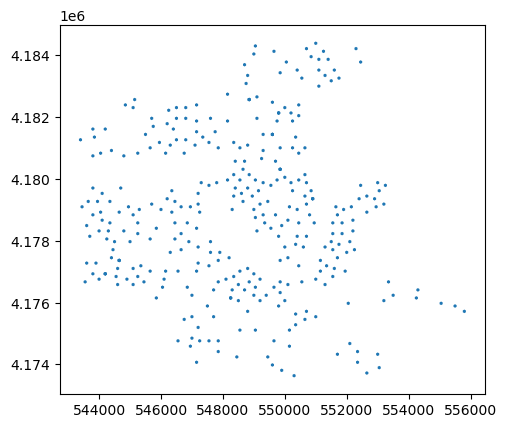

In [40]:
# Set the active geometry column to geometry_x
df6_geo = df6_geo.set_geometry('geometry_x')


df6_geo.plot()


In [ ]:

# Then save to GeoJSON

df6_geo.to_file('./data/SF_final_alljoin_hex_05_01_26.geojson', driver='GeoJSON')

AttributeError: 'float' object has no attribute 'encode'

# Habitat

In [41]:
#combine both the raster/polygon datasets and add in inext values 
#Use the df5 from the last cell 



# Load all the different dataframes with proper names

inext_data_human = pd.read_csv("./data/SF/inext_results/ebird_human_inc_covstd_0.8.csv")
inext_data_shrubgrass = pd.read_csv("./data/SF/inext_results/ebird_shrubgrass_inc_covstd_0.8.csv")
inext_data_tree = pd.read_csv("./data/SF/inext_results/ebird_trees_inc_covstd_0.8.csv")
inext_data_water = pd.read_csv("./data/SF/inext_results/ebird_water_inc_covstd_0.8.csv")
inext_data_native = pd.read_csv("./data/SF/inext_results/ebird_native_inc_covstd_0.8.csv")
inext_data_nonnative = pd.read_csv("./data/SF/inext_results/ebird_non-native_inc_covstd_0.8.csv")



In [42]:
import itertools

res_dir = "/home/oliver/Documents/redlining/data/SF/inext_results"
LEVEL = 0.8
q_names = {0: "Species richness", 1: "Shannon diversity", 2: "Simpson diversity"}

groups = {"human": "human", "water": "water", "tree": "trees", "shrubgrass": "shrubgrass",
          "native": "native", "nonnative": "non-native"}   # column name -> file name

def load_covstd(file_key):
    df = pd.read_csv(f"{res_dir}/ebird_{file_key}_inc_covstd_{LEVEL}.csv")
    df = df.rename(columns={"Assemblage": "label", "qD": "Estimator",
                            "qD.LCL": "LCL", "qD.UCL": "UCL"})
    df["label"] = df["label"].astype(str).str.strip().str.lstrip("X").str.upper()
    df["Diversity"] = df["Order.q"].map(q_names)
    return df[["label", "Diversity", "Estimator", "LCL", "UCL", "beyond_2T"]]

inext = {name: load_covstd(f) for name, f in groups.items()}

# Base table: every hexagon x diversity order (hexagons that failed for a group stay NaN)
all_labels = sorted(set().union(*[d["label"] for d in inext.values()]))
base_df = pd.DataFrame(itertools.product(all_labels, q_names.values()), columns=["label", "Diversity"])

result_df = base_df.copy()
for name, d in inext.items():
    d = d.rename(columns={"Estimator": f"{name}_estimate", "LCL": f"{name}_lcl",
                          "UCL": f"{name}_ucl", "beyond_2T": f"{name}_beyond2T"})
    result_df = result_df.merge(d, on=["label", "Diversity"], how="left")

# Grade from the hexagon ID; hexagon covariates by hex_id (NOT holc_prj on label)
result_df = result_df.rename(columns={"label": "hex_id"})
result_df["grade"] = result_df["hex_id"].str.split("_").str[-1]

print("Final dataframe shape:", result_df.shape)
print(result_df.head())
print("\nMissing estimates per group (failed or group absent):")
print(result_df.filter(like="_estimate").isna().groupby(result_df["Diversity"]).sum())


Final dataframe shape: (459, 27)
   hex_id          Diversity  human_estimate  human_lcl  human_ucl  \
0  1014_B   Species richness        3.259879   2.636035   3.883723   
1  1014_B  Shannon diversity        2.881002   2.264171   3.497833   
2  1014_B  Simpson diversity        2.570356   1.956598   3.184113   
3  1030_B   Species richness             NaN        NaN        NaN   
4  1030_B  Shannon diversity             NaN        NaN        NaN   

  human_beyond2T  water_estimate  water_lcl  water_ucl water_beyond2T  ...  \
0          False        2.171429   0.167721   4.175136          False  ...   
1          False        2.088451   0.002324   4.174578          False  ...   
2          False        2.011991   0.000000   4.250810          False  ...   
3            NaN             NaN        NaN        NaN            NaN  ...   
4            NaN             NaN        NaN        NaN            NaN  ...   

   shrubgrass_beyond2T  native_estimate  native_lcl native_ucl  \
0          

In [ ]:
""" 
# Check column names in each dataframe
print("Column names in each dataframe:")
for df_name, df in {
    'all': inext_data_all,
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native' : inext_data_native,
    'nonnative' : inext_data_nonnative
}.items():
    print(f"{df_name}: {df.columns.tolist()}")

# Standardize column names across all dataframes
for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'Assemblage' in df.columns:
        df.rename(columns={'Assemblage': 'label'}, inplace=True)
    
    # Clean IDs for consistency
    if 'label' in df.columns:
        df['label'] = df['label'].str.strip().str.upper()

# Create the base dataframe with unique combinations of label and Diversity
# First, collect all unique labels and diversity metrics
all_labels = set()
all_diversity = set()

for df in [inext_data_all, inext_data_human, inext_data_water, inext_data_tree, inext_data_shrubgrass, inext_data_native, inext_data_nonnative]:
    if 'label' in df.columns:
        all_labels.update(df['label'].unique())
    if 'Diversity' in df.columns:
        all_diversity.update(df['Diversity'].unique())

# Convert sets to lists for DataFrame creation
all_labels = list(all_labels)
all_diversity = list(all_diversity)

# Create all combinations
import itertools
combinations = list(itertools.product(all_labels, all_diversity))
base_df = pd.DataFrame(combinations, columns=['label', 'Diversity'])

# Function to add each habitat's estimates
def add_habitat_estimates(base_df, habitat_df, habitat_name):
    """
    Adds estimate columns from a habitat dataset to the base dataframe
    """
    # Make a copy of the input dataframe
    df = habitat_df.copy()
    
    # Ensure we have the correct column names
    if 'Estimator' in df.columns:
        # Create a new dataframe with the columns we need
        temp_df = df[['label', 'Diversity', 'Estimator']].copy()
        # Rename the estimate column
        temp_df = temp_df.rename(columns={'Estimator': f'{habitat_name}_estimate'})
        
        # Merge with the base dataframe
        merged_df = base_df.merge(temp_df, on=['label', 'Diversity'], how='left')
        return merged_df
    else:
        print(f"Warning: 'Estimator' column not found in {habitat_name} dataframe. Columns: {df.columns.tolist()}")
        return base_df

# Start with the base dataframe
result_df = base_df.copy()

# Add estimates from each habitat type
habitat_types = {
    'human': inext_data_human,
    'water': inext_data_water,
    'tree': inext_data_tree,
    'shrubgrass': inext_data_shrubgrass,
    'native': inext_data_native,
    'nonnative': inext_data_nonnative,
    'all': inext_data_all
}

for habitat_name, habitat_df in habitat_types.items():
    print(f"Processing {habitat_name} habitat data...")
    result_df = add_habitat_estimates(result_df, habitat_df, habitat_name)

# Add additional columns from holc_prj 
# (First, make sure 'label' in holc_prj is standardized)
if 'label' in holc_prj.columns:
    holc_prj['label'] = holc_prj['label'].str.strip().str.upper()
    
    # Add all columns except 'label' (which is already in result_df)
    other_columns = [col for col in holc_prj.columns if col != 'label']
    if other_columns:  # Only merge if there are columns to add
        result_df = result_df.merge(holc_prj[['label'] + other_columns], on='label', how='left')

# Display the results
print("\nFinal dataframe shape:", result_df.shape)
print("Columns in final dataframe:", result_df.columns.tolist())
print("\nSample rows from final dataframe:")
print(result_df.head())

# Check for missing values
print("\nMissing value counts by column:")
print(result_df.isna().sum()) """

Column names in each dataframe:
all: ['Unnamed: 0', 'label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
human: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
water: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
tree: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
shrubgrass: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
native: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
nonnative: ['label', 'Diversity', 'Observed', 'Estimator', 's.e.', 'LCL', 'UCL']
Processing human habitat data...
Processing water habitat data...
Processing tree habitat data...
Processing shrubgrass habitat data...
Processing native habitat data...
Processing nonnative habitat data...
Processing all habitat data...

Final dataframe shape: (759, 20)
Columns in final dataframe: ['label', 'Diversity', 'human_estimate', 'water_estimate', 'tree_estimate', 'shrubgrass_estimate', 'native_e

In [ ]:
result_df.shape

(459, 27)

In [44]:
#Now let's join everything by label id (Make sure that there's only 333 unique hex id per diversity type)


#result_df from inext estimates
#raster_df
#polygon_df 
final = df5.merge(result_df, on = ['hex_id'], how='left', suffixes=("", "_inext"))
#final = df6.merge(df5, on = 'label', how='left' )
 
final.shape
final.columns
final.groupby('hex_id').size()


hex_id
1003_B    1
1014_B    3
1030_B    3
1037_C    1
1080_A    3
         ..
838_B     3
840_B     1
847_B     3
865_B     3
877_B     1
Length: 333, dtype: int64

In [45]:
#Let's also add in effort too 

#Add in efforts from ebird 
import duckdb
import numpy as np

con = duckdb.connect()
pq = "/home/oliver/Documents/data/output/ebird_hex_joined.parquet"

effort = con.execute(f"""
    WITH chk AS (               -- one row per checklist (the parquet repeats each checklist per species)
        SELECT DISTINCT hex_id, checklist_id, effort_hours, duration_minutes,
                        observer_id, protocol_name, number_observers
        FROM read_parquet('{pq}')
    )
    SELECT hex_id,
           COUNT(*)                                                    AS n_checklists,
           SUM(effort_hours)                                           AS total_hours,
           AVG(duration_minutes)                                       AS mean_duration_min,
           COUNT(DISTINCT observer_id)                                 AS n_observers,
           AVG(CASE WHEN protocol_name = 'Traveling' THEN 1.0 ELSE 0 END) AS prop_traveling,
           AVG(number_observers)                                       AS mean_party_size
    FROM chk
    GROUP BY hex_id
""").df()

effort["log_total_hours"]  = np.log(effort["total_hours"])
effort["log_n_checklists"] = np.log(effort["n_checklists"])

print(effort.describe().round(2))
print(effort[["log_n_checklists", "log_total_hours", "n_observers", "prop_traveling"]].corr().round(2))


       n_checklists  total_hours  mean_duration_min  n_observers  \
count        715.00       715.00             715.00       715.00   
mean          13.02         9.48              35.17         3.06   
std           62.73        52.99              21.05        14.26   
min            1.00         0.25              15.00         1.00   
25%            1.00         0.38              20.00         1.00   
50%            2.00         1.00              29.67         1.00   
75%            4.00         2.25              44.00         1.00   
max          976.00       718.40             120.00       232.00   

       prop_traveling  mean_party_size  log_total_hours  log_n_checklists  
count          715.00           715.00           715.00            715.00  
mean             0.25             1.31             0.23              0.91  
std              0.40             0.74             1.48              1.28  
min              0.00             1.00            -1.39              0.00  
25%    

In [46]:
final = final.merge(effort, on="hex_id", how="left")
print(f"Hexagons without effort data: {final.loc[final['n_checklists'].isna(), 'hex_id'].nunique()}")   # should be 0



Hexagons without effort data: 0


In [47]:
import geopandas as gpd
from shapely import wkt

holc = (gpd.read_file("/home/oliver/Documents/redlining/data/SF/dependent_var/SF_HOLC_cleaned.geojson")
          .to_crs(32610)[["area_id", "label", "grade", "geometry"]]
          .rename(columns={"area_id": "holc_id", "label": "holc_label", "grade": "holc_grade"}))

# One geometry per hexagon (final has 3 rows per hexagon, one per q)
hex_geom = final[["hex_id", "geometry_x"]].drop_duplicates("hex_id").copy()
if isinstance(hex_geom["geometry_x"].iloc[0], str):           # read from CSV, so WKT text
    hex_geom["geometry_x"] = hex_geom["geometry_x"].apply(wkt.loads)
hex_geom = gpd.GeoDataFrame(hex_geom, geometry="geometry_x", crs=32610)
# If the hexagons aren't already in EPSG:32610, use .set_crs(<their CRS>).to_crs(32610) instead

# Largest-overlap HOLC polygon for each hexagon
ov = gpd.overlay(hex_geom, holc, how="intersection", keep_geom_type=True)
ov["overlap_m2"] = ov.area
holc_lookup = (ov.sort_values("overlap_m2", ascending=False)
                 .drop_duplicates("hex_id")[["hex_id", "holc_id", "holc_label", "holc_grade"]])

final = final.merge(holc_lookup, on="hex_id", how="left")

# Checks
print(f"Hexagons without holc_id: {final.loc[final['holc_id'].isna(), 'hex_id'].nunique()}")   # should be 0
print(f"Grade mismatches: {(final['grade'] != final['holc_grade']).sum()}")                   # should be 0
print(f"Neighbourhoods: {final['holc_id'].nunique()}")
print(final.drop_duplicates("hex_id").groupby("holc_id").size().describe())                 # hexagons per neighbourhood

#Drop any NAs
final = final[final["Diversity"].notna()]


Hexagons without holc_id: 0
Grade mismatches: 180
Neighbourhoods: 83
count    83.000000
mean      4.012048
std       3.970912
min       1.000000
25%       1.500000
50%       3.000000
75%       5.000000
max      26.000000
dtype: float64


In [48]:
final.head()

,hex_id,geometry_x,min_ndvi,max_ndvi,mean_ndvi,count_ndvi,std_ndvi,median_ndvi,majority_ndvi,min_highway,...,total_hours,mean_duration_min,n_observers,prop_traveling,mean_party_size,log_total_hours,log_n_checklists,holc_id,holc_label,holc_grade
1,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4...",0.213248,0.669190,0.378044,1048,0.093760,0.351401,0.328507,2583.555664,...,1.416667,42.500000,1,0.000000,1.0,0.348307,0.693147,754,C15,C
2,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4...",0.213248,0.669190,0.378044,1048,0.093760,0.351401,0.328507,2583.555664,...,1.416667,42.500000,1,0.000000,1.0,0.348307,0.693147,754,C15,C
3,21_C,"POLYGON ((543445.991 4179036.521, 543395.991 4...",0.213248,0.669190,0.378044,1048,0.093760,0.351401,0.328507,2583.555664,...,1.416667,42.500000,1,0.000000,1.0,0.348307,0.693147,754,C15,C
4,44_B,"POLYGON ((543545.991 4176611.65, 543495.991 41...",0.218430,0.544557,0.316655,1030,0.057492,0.301282,0.277842,728.277405,...,53.066667,27.686957,1,0.052174,1.0,3.971549,4.744932,758,B758,B
5,44_B,"POLYGON ((543545.991 4176611.65, 543495.991 41...",0.218430,0.544557,0.316655,1030,0.057492,0.301282,0.277842,728.277405,...,53.066667,27.686957,1,0.052174,1.0,3.971549,4.744932,758,B758,B


In [49]:
final.to_csv('/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/data/Results/SF_final_alljoin_hex_11.16.26.csv', index=False)

Now we move onto Random Forest modelling